# Case Study: Edge Detection

In [ ]:
import os
# Keras backend: "tensorflow" (default) or "torch". Must be set before keras is imported.
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

In [1]:
import numpy as np
from io import BytesIO

from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_context('talk')
%config InlineBackend.figure_format ='retina'

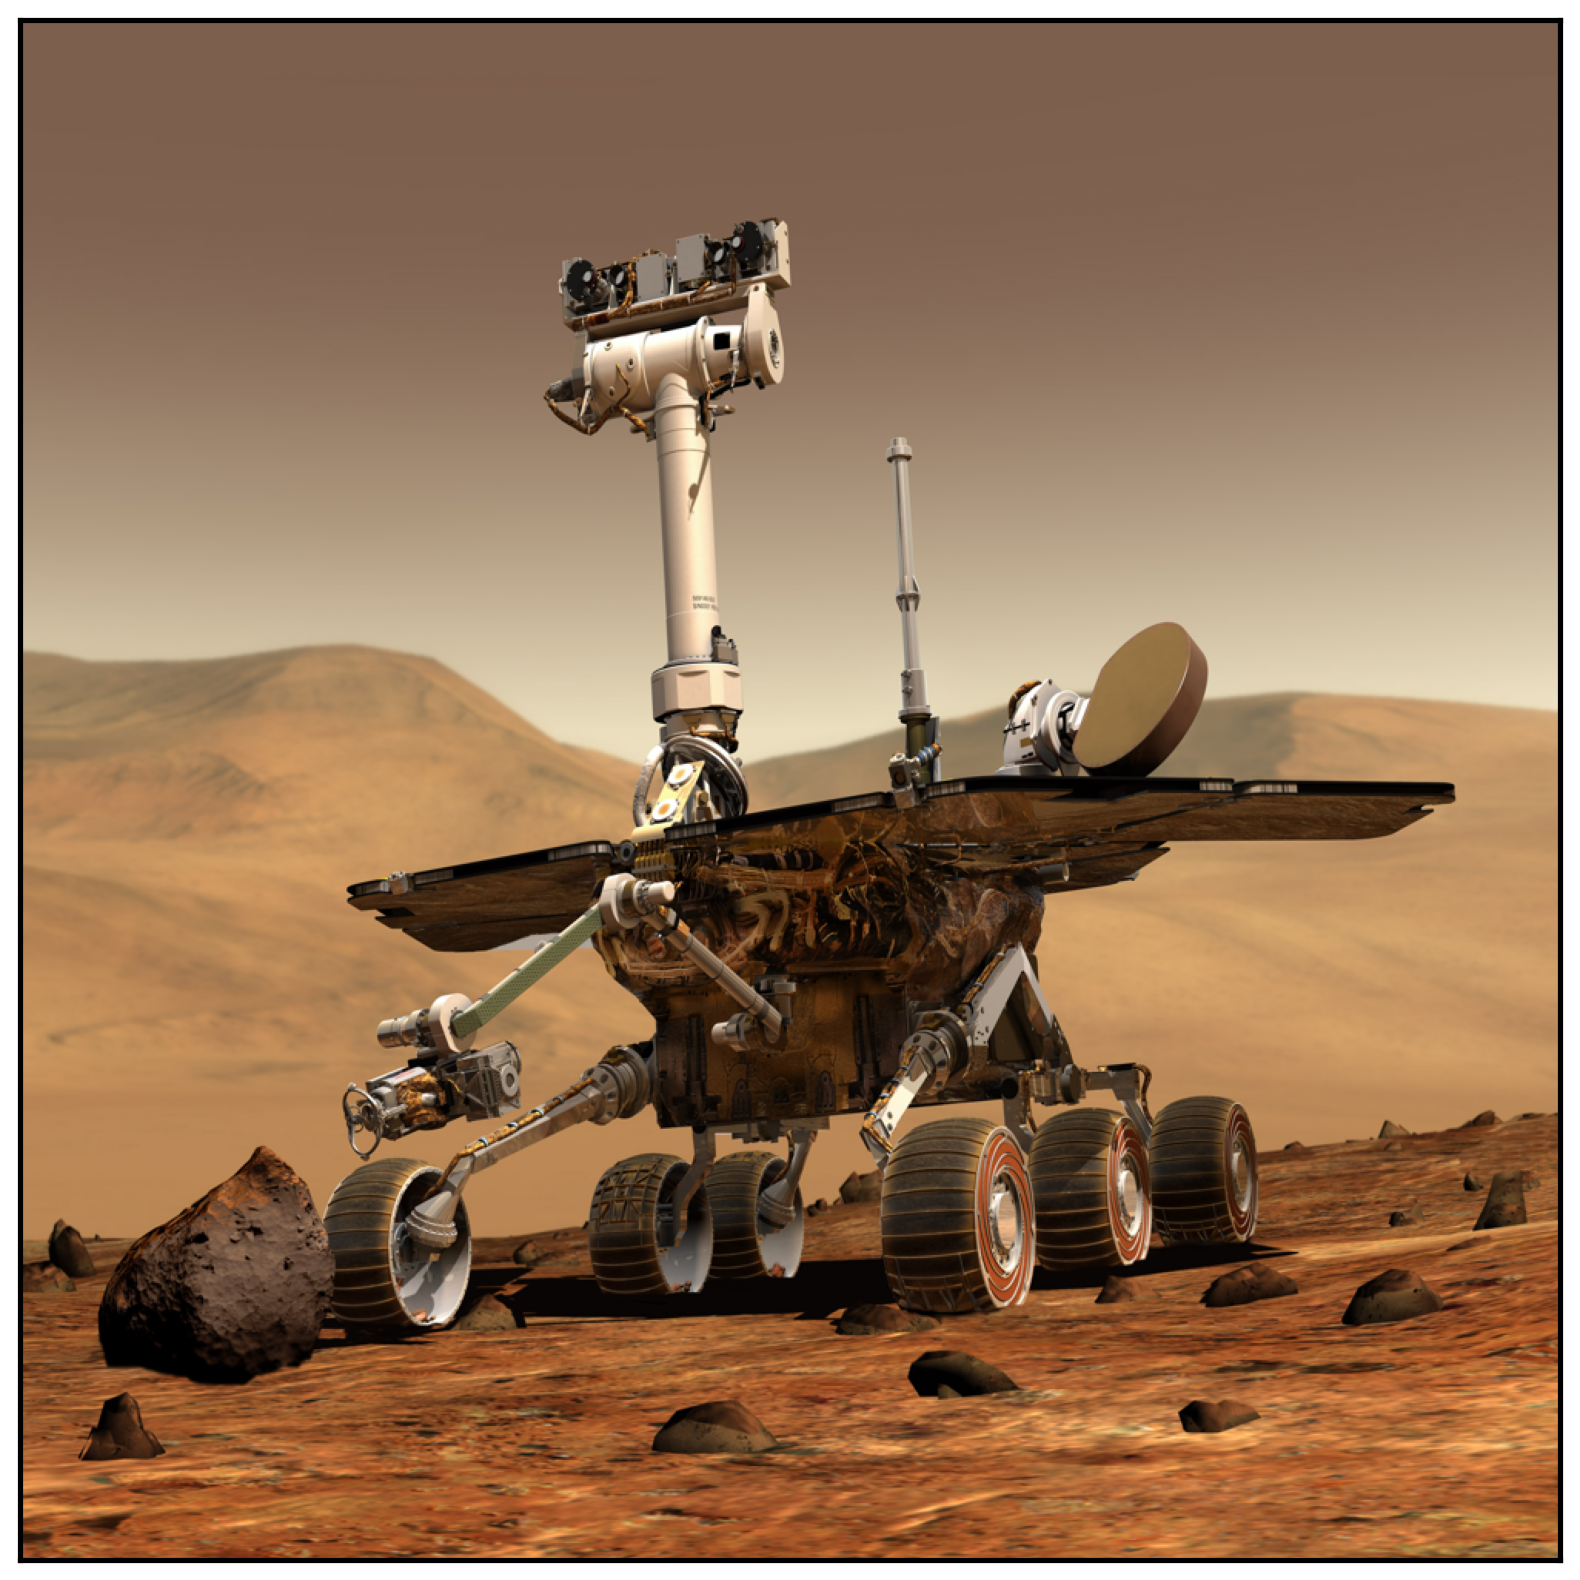

In [2]:
pixels = plt.imread('NASA_Mars_Rover.jpeg')
image = Image.fromarray(pixels)

pixels_scaled = {
    p: np.array(image.resize([p, p], Image.Resampling.BICUBIC)).astype(float) / 255
    for p in [100, 300, 600, 1000]
}

plt.figure(figsize=[10, 10])
plt.imshow(pixels_scaled[1000])
plt.xticks([])
plt.yticks([])
plt.show()

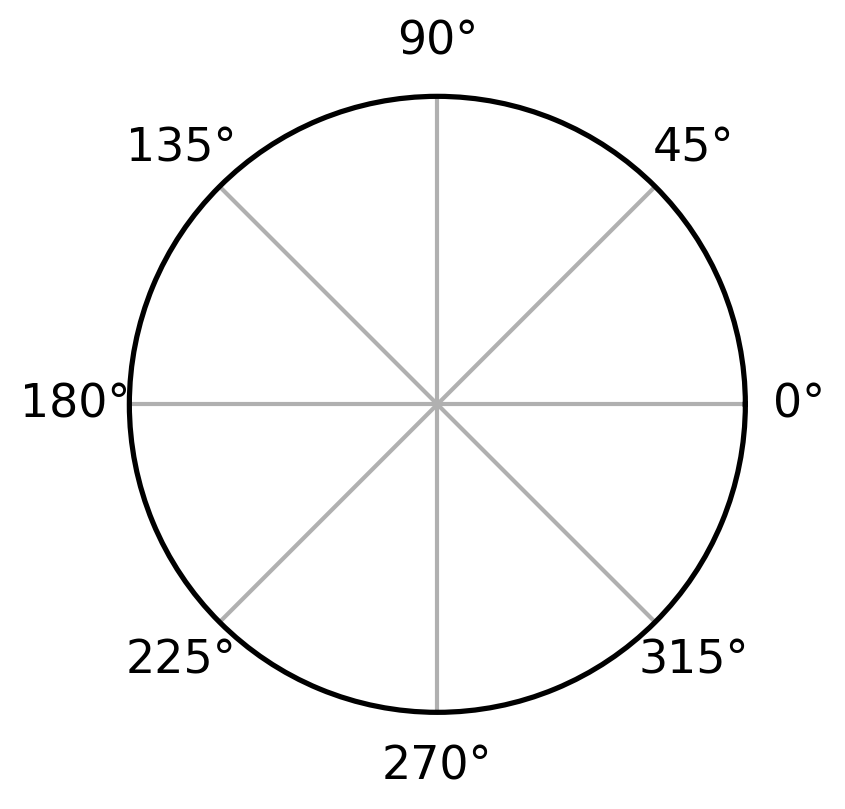

In [3]:
import matplotlib.pyplot as plt
plt.figure(figsize=[4, 4])
plt.polar()
plt.yticks([])
plt.show()

In [4]:
# Run this cell to configure the GPU.
import keras
print("Keras backend:", keras.backend.backend())
if keras.backend.backend() == "tensorflow":
    import tensorflow as tf
    # Let TensorFlow allocate GPU memory as needed instead of grabbing all of it.
    for gpu in tf.config.list_physical_devices('GPU'):
        print(gpu)
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    import torch
    print("PyTorch device:", torch.cuda.get_device_name() if torch.cuda.is_available() else "cpu")

PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


I0000 00:00:1728239234.180980  737143 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1728239234.235803  737143 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1728239234.238932  737143 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355


In [5]:
from keras import ops

# Convolution via Keras for a single multi-channel image,
# and a four-dimensional filter (h, w, in, out). Padding is same,
# while strides are 1. Additionally, a sigmoid activation is applied.
def conv2d(image: np.ndarray, kernel: np.ndarray):
    
    # Desired input shape = (batch, height, width, channel),
    # so we need to add 0th axis.
    image_batch = np.expand_dims(image, 0)
    image_tensor = ops.convert_to_tensor(image_batch)

    # Filter weights
    filter_tensor = ops.convert_to_tensor(kernel, dtype="float64")

    # Convolution operation
    conv_tensor = ops.conv(
        image_tensor, 
        filter_tensor,
        strides=1,
        padding="same"
    )

    activation_tensor = conv_tensor
    
    # In order to visualize activations, we need
    # to bound the values in [0, 1] range.
    activation_tensor = ops.sigmoid(activation_tensor) - 0.5
    activation_tensor = activation_tensor / ops.max(activation_tensor)

    # Copy the result from the backend (and possibly the GPU) into a NumPy array.
    return ops.convert_to_numpy(activation_tensor[0])

In [6]:
# Define 4 different 3x3 filters
filters = {
    '0 degrees': [
        [-1, -1, -1],
        [ 0,  0,  0],
        [ 1,  1,  1]
    ],
 
    '45 degrees': [
        [-1, -1,  0],
        [-1,  0,  1],
        [ 0,  1,  1]
    ],
    
    '90 degrees': [
        [-1, 0, 1],
        [-1, 0, 1],
        [-1, 0, 1]
    ],
    
    '135 degrees': [
        [ 0,  1, 1],
        [-1,  0, 1],
        [-1, -1, 0]
    ]
}

filters['180 degrees'] = -1 * np.array(filters['0 degrees'])
filters['225 degrees'] = -1 * np.array(filters['45 degrees'])
filters['270 degrees'] = -1 * np.array(filters['90 degrees'])
filters['315 degrees'] = -1 * np.array(filters['135 degrees'])

filter_names = list(filters.keys())

# Duplicate the filters across every image channel
filters = np.array([
    np.repeat(np.array(f), 3).reshape(3, 3, 3).astype('float64')
    for n, f in filters.items()
])

# Currently, the output channel is the 1st dimension
# However, Keras requires the output channel to be 4th
filters = np.moveaxis(filters, 0, 3)

input_image = pixels_scaled[300]
activation = conv2d(input_image, filters)

I0000 00:00:1728239234.264061  737143 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1728239234.267005  737143 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1728239234.269727  737143 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1728239234.431573  737143 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

In [7]:
{
    'input_image': (input_image.shape, input_image.dtype),
    'filter_shape': (filters.shape, filters.dtype),
    'output_shape': (activation.shape, activation.dtype)
}

{'input_image': ((300, 300, 3), dtype('float64')),
 'filter_shape': ((3, 3, 3, 8), dtype('float64')),
 'output_shape': (TensorShape([300, 300, 8]), tf.float64)}

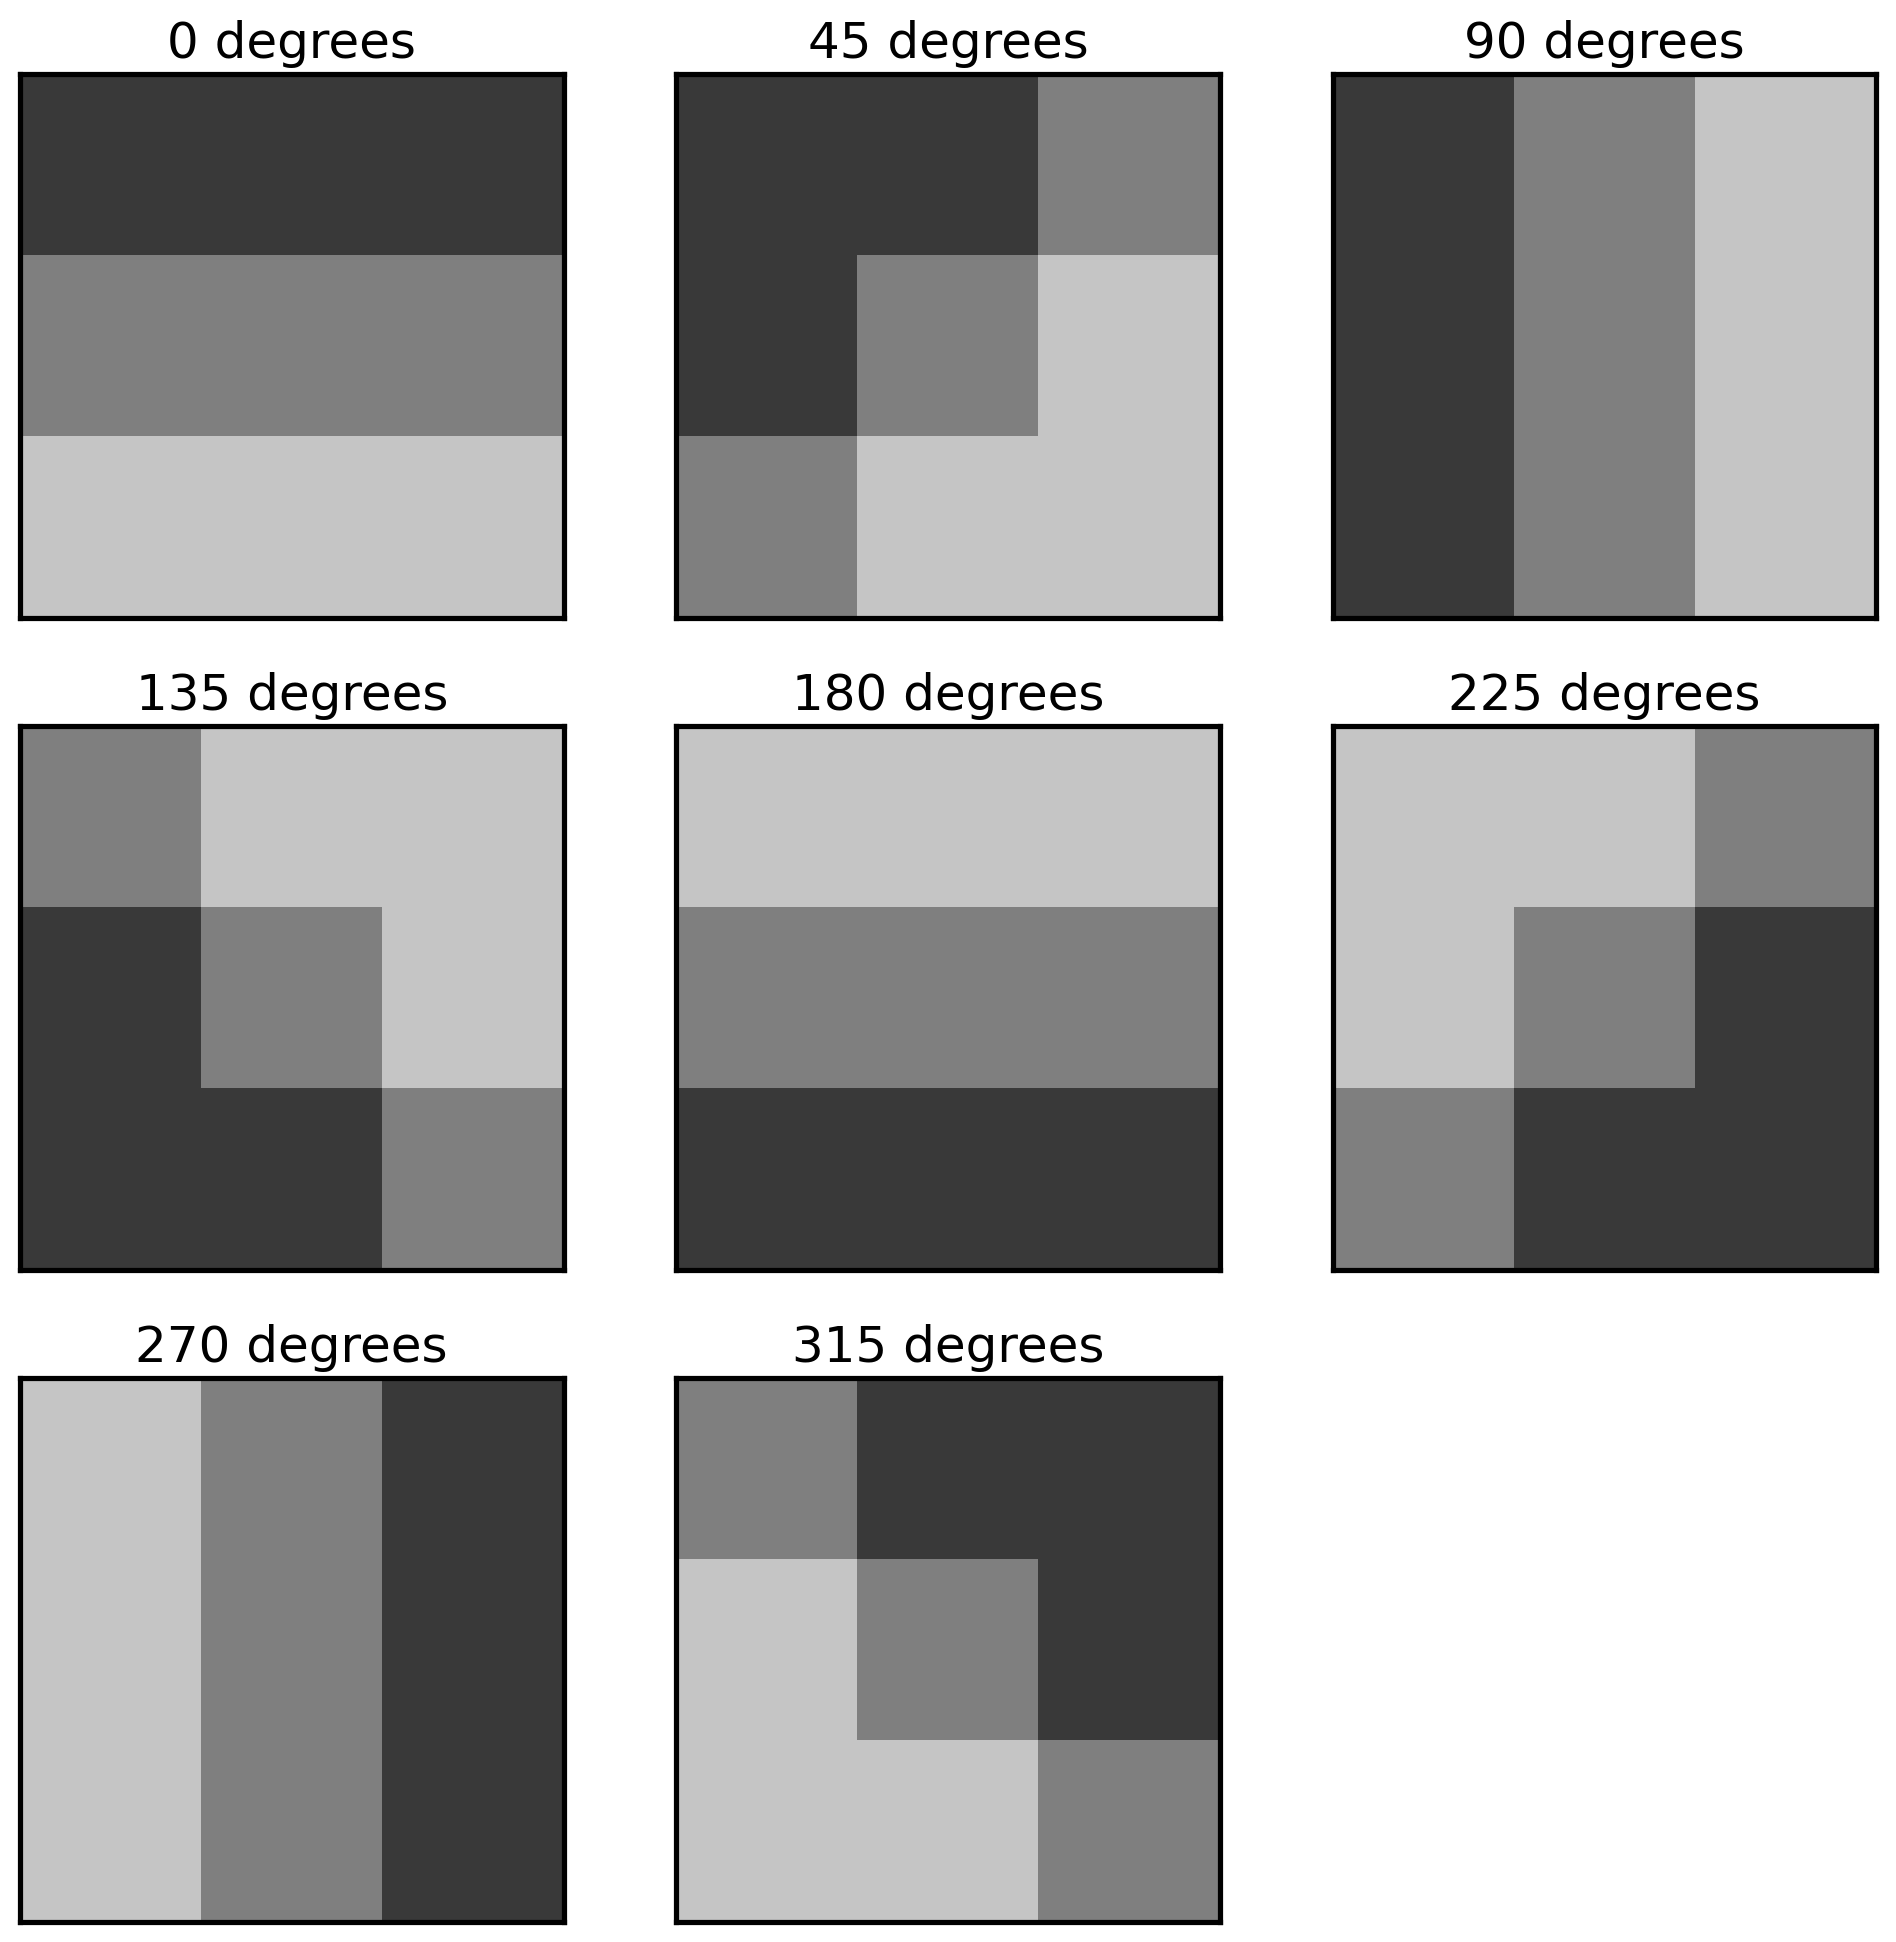

In [8]:
from utils.plot import plot_conv_kernel
plot_conv_kernel(filters, labels=filter_names, side_inches=4)

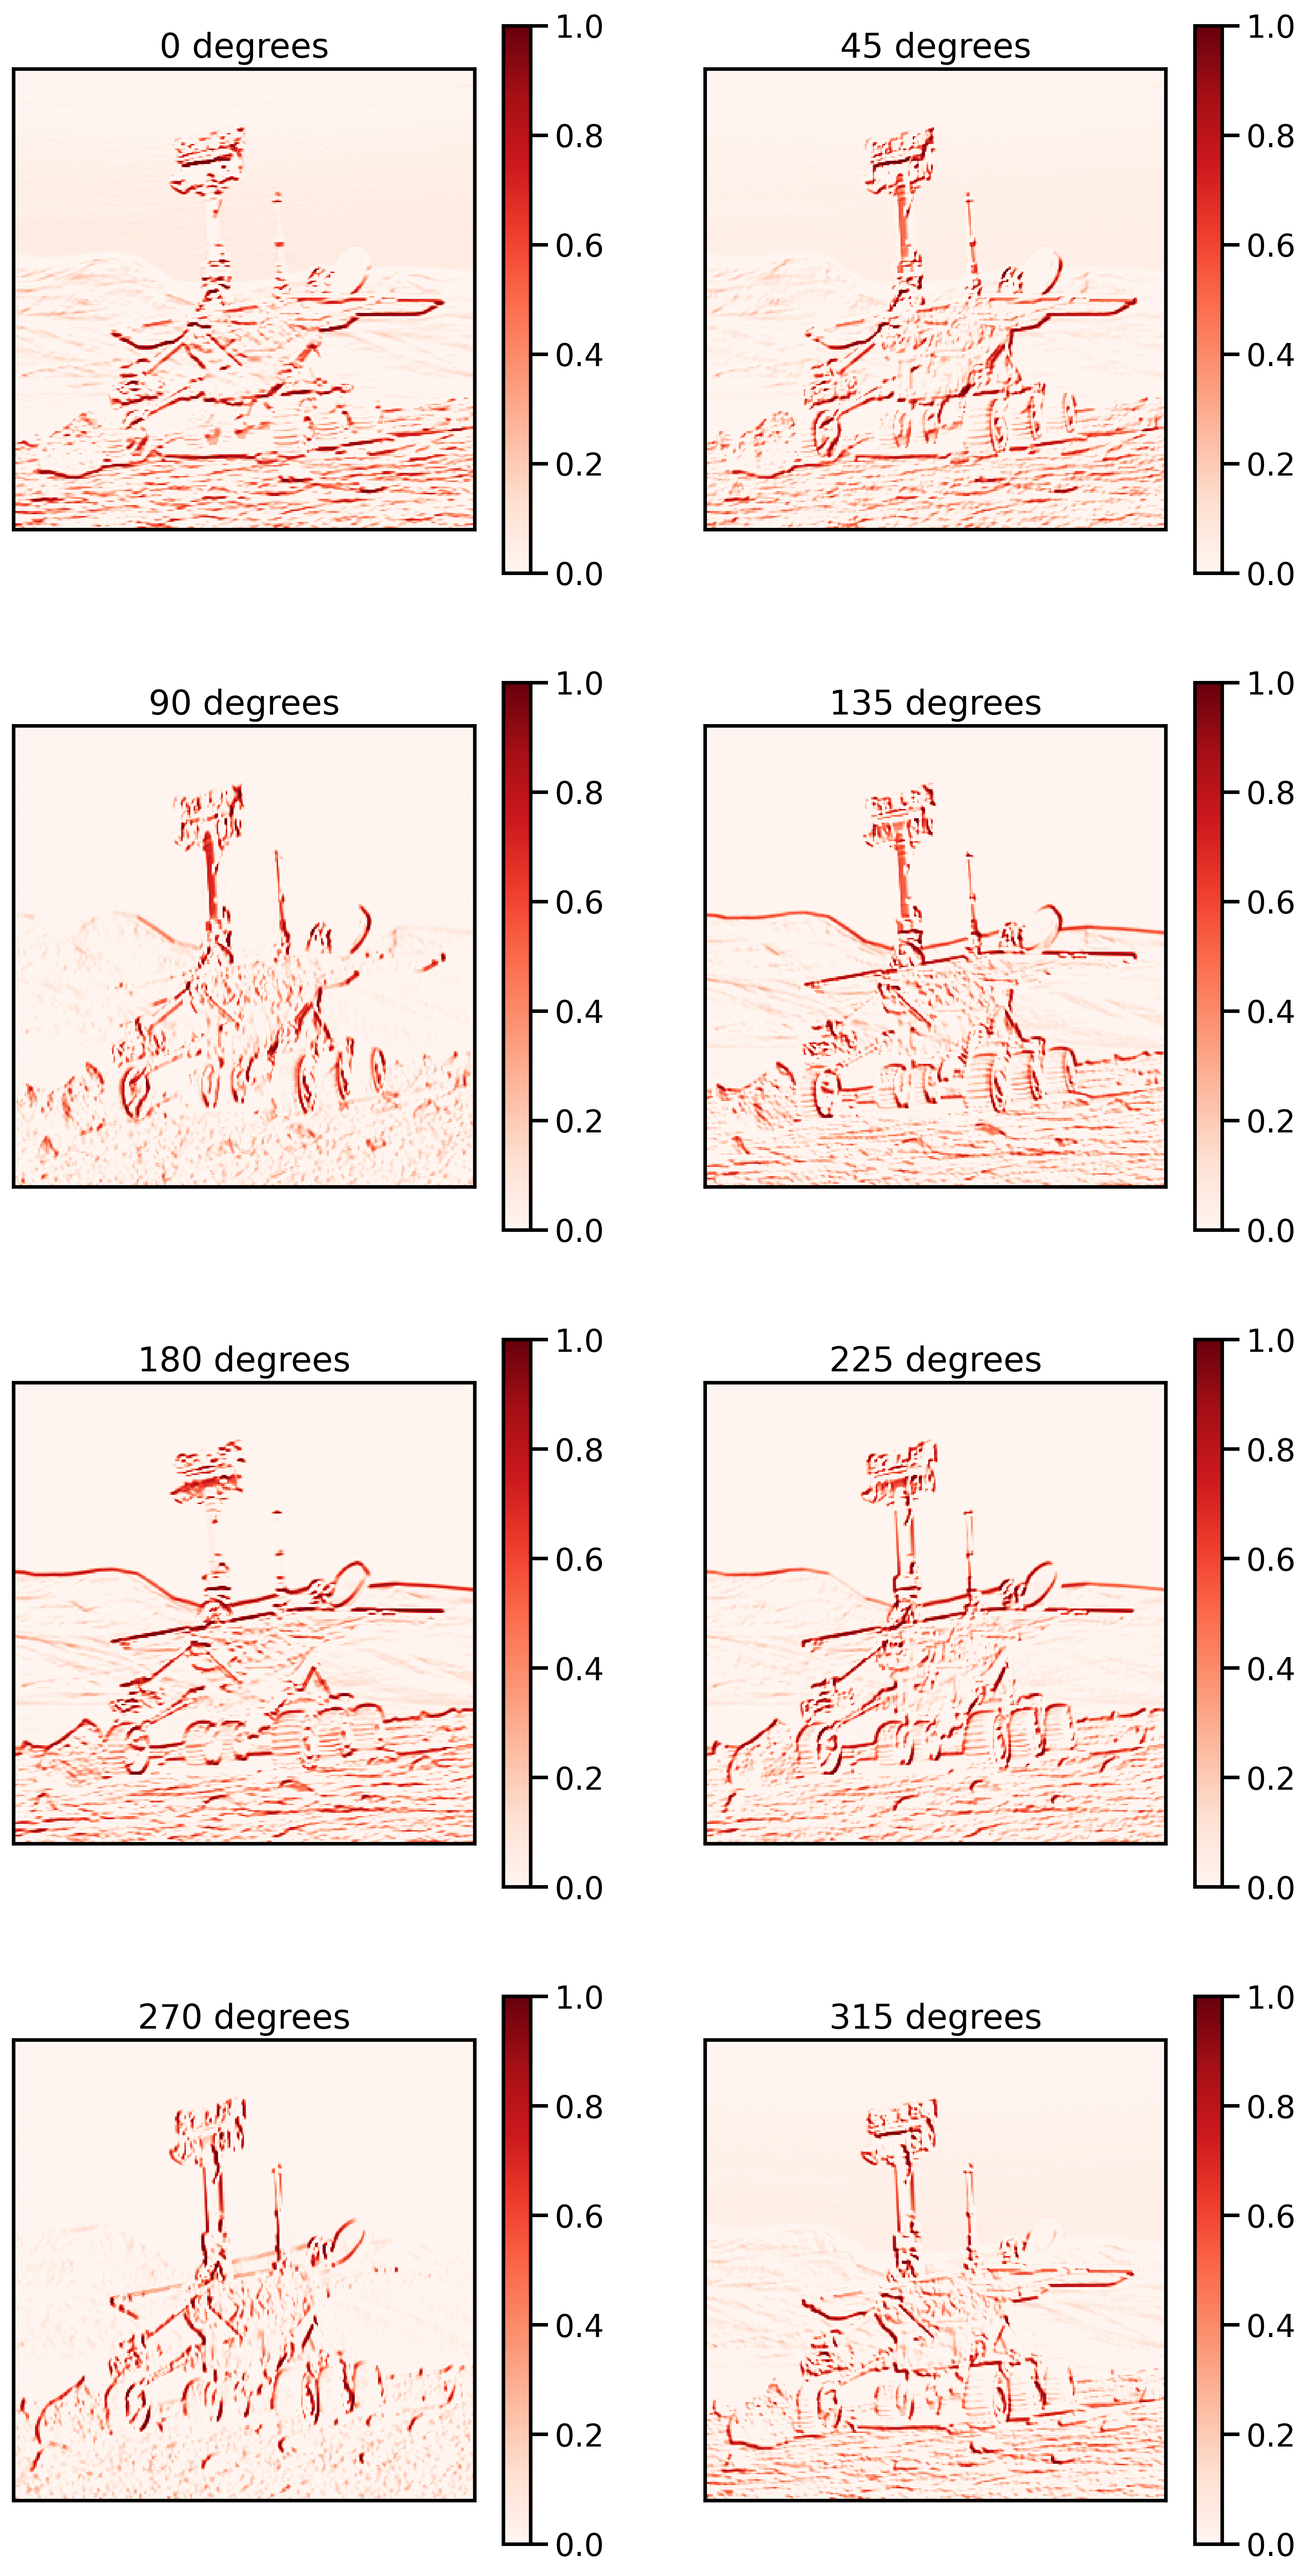

In [12]:
import matplotlib.pyplot as plt
import math

cols = 2
rows = math.ceil(len(filter_names) / cols)
fig = plt.figure(figsize=[6 * cols, 6 * rows], dpi=150)

for idx, name in enumerate(filter_names):
    ax = plt.subplot(rows, cols, idx+1)
    plt.title(name)
    plt.yticks([])
    plt.xticks([])
    pos = plt.imshow(
        activation[:, :, idx], 
        cmap=plt.get_cmap('Reds'), 
        vmin=0, 
        vmax=1
    )
    cb = fig.colorbar(pos, ax=ax)

In [10]:
def max_pool(image: np.ndarray, surface_size: int, depth_size: int):
    image_tensor = ops.convert_to_tensor(np.expand_dims(image, 0))

    if depth_size > 1:
        # Max pooling over depth: keep the strongest activation
        # across depth_size neighbouring channels at every pixel.
        # Pooling layers only slide over height and width,
        # so we reshape the channels into groups and take their maximum.
        height, width, channels = image.shape
        groups = ops.reshape(image_tensor, (1, height, width, channels // depth_size, depth_size))
        max_pool_tensor = ops.max(groups, axis=-1)
    else:
        # Max pooling over height and width (each channel separately).
        max_pool_tensor = ops.max_pool(
            image_tensor,
            pool_size=surface_size,
            strides=1,
            padding="valid",
        )

    return ops.convert_to_numpy(max_pool_tensor[0])
    
input_channels = activation.shape[2]
activations_by_window = {
    (surface_size, depth_size): max_pool(activation[:, :, :], surface_size, depth_size)
    for surface_size, depth_size in [(1, input_channels), (5, 1), (10, 1), (30, 1)]
}

{w: a.shape for w, a in activations_by_window.items()}

{(1, 8): TensorShape([300, 300, 1]),
 (5, 1): TensorShape([296, 296, 8]),
 (10, 1): TensorShape([291, 291, 8]),
 (30, 1): TensorShape([271, 271, 8])}

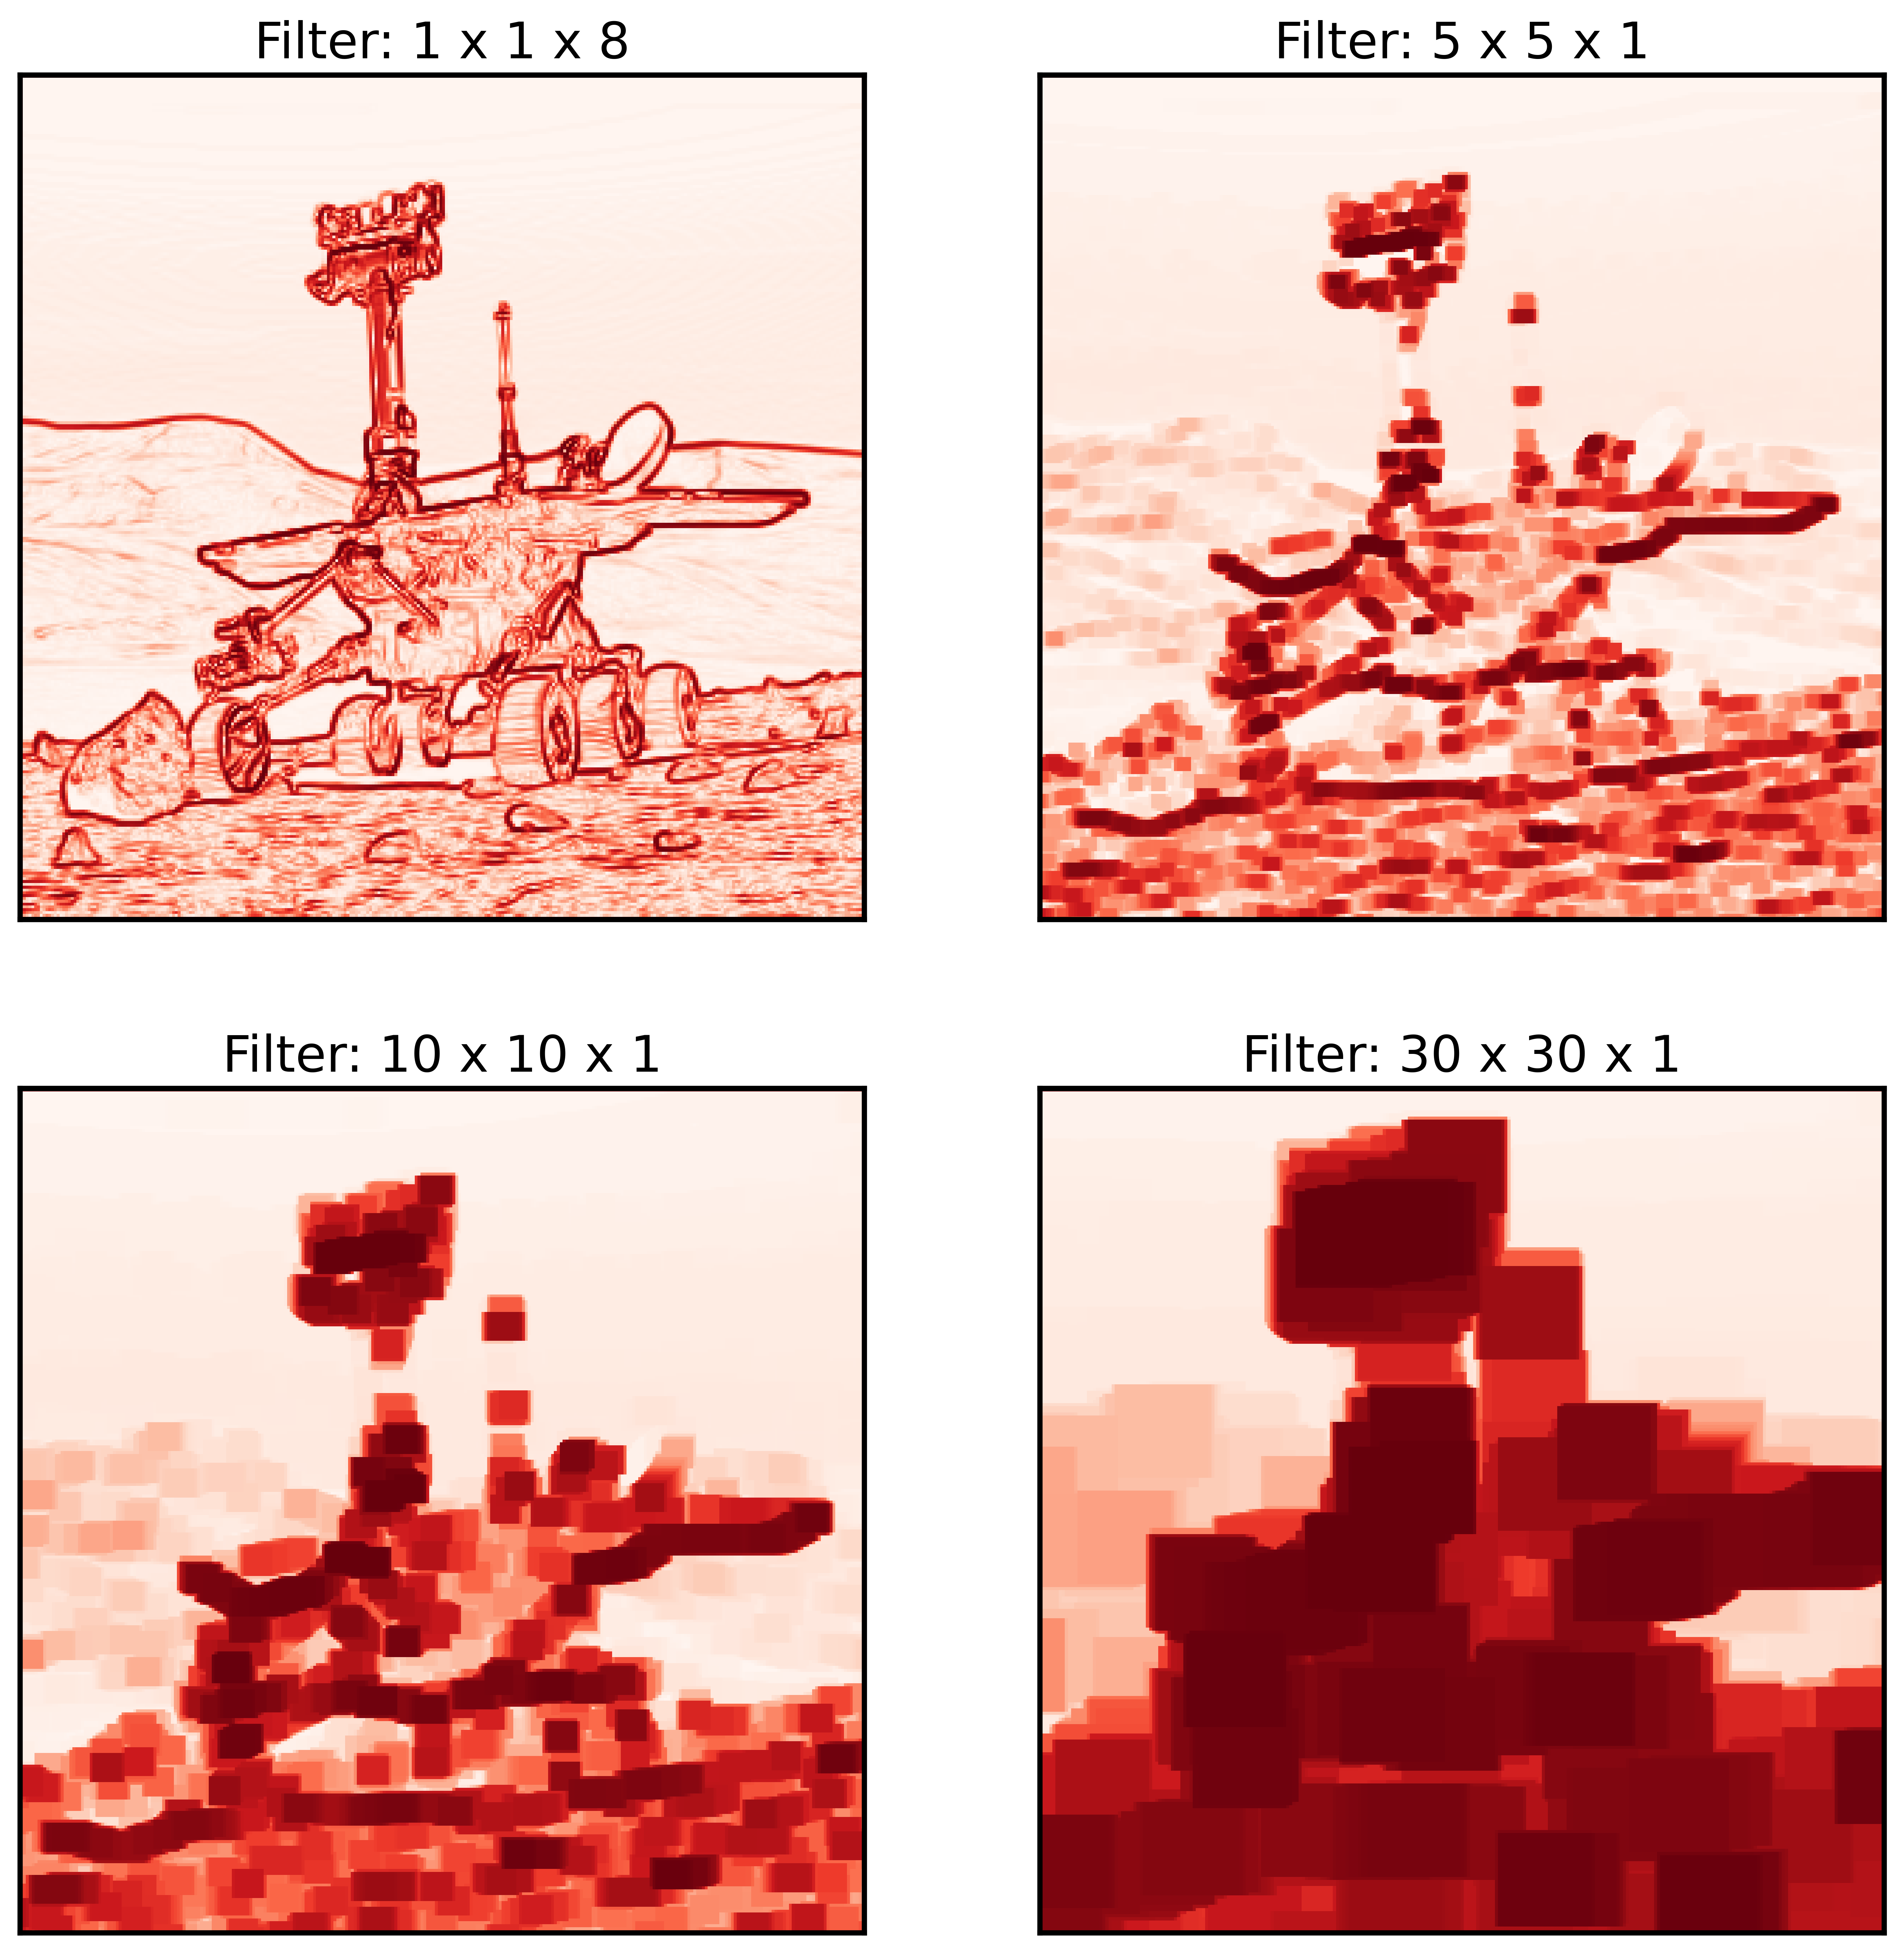

In [11]:
cols = 2
rows = math.ceil(len(activations_by_window.keys()) / cols)

plt.figure(figsize=[6 * cols, 6 * rows], dpi=300)

for idx, ((surface_size, depth_size), image) in enumerate(activations_by_window.items()):
    plt.subplot(rows, cols, idx+1)
    plt.title(f'Filter: {surface_size} x {surface_size} x {depth_size}')
    plt.xticks([])
    plt.yticks([])
    plt.imshow(
        image[:, :, 0], 
        cmap=plt.get_cmap('Reds'), 
        vmin=0, 
        vmax=1
    )